In [40]:
import itertools
import numpy as np
import lal
import lalsimulation as lalsim

# ---------------- prior (from your yaml) ----------------
MC_RANGE  = (50.0, 1200.0)    # detector-frame chirp mass [Msun]
Q_RANGE   = (0.125, 1.0)
M1_RANGE  = (50.0, 4500.0)
M2_RANGE  = (20.0, 1500.0)
CHI_RANGE = (-0.9, 0.9)       # AlignedSpin(a_prior=Uniform(0, 0.9)) -> chi_z in [-0.9, 0.9]
F_MIN     = 6.0
F_REF     = 20.0
DIST_MPC  = 1000.0
APPROX    = lalsim.IMRPhenomXPHM

In [41]:
def comp_masses(mc, q):
    m1 = mc * (1 + q) ** 0.2 / q ** 0.6
    return m1, q * m1


def in_prior(m1, m2):
    return M1_RANGE[0] <= m1 <= M1_RANGE[1] and M2_RANGE[0] <= m2 <= M2_RANGE[1]


def duration_bound(m1, m2, s1z, s2z, f_min=F_MIN):
    """Returns (t_pre, t_post) upper bounds in s; masses in detector-frame Msun."""
    m1_kg, m2_kg = m1 * lal.MSUN_SI, m2 * lal.MSUN_SI
    M = m1 + m2
    f_isco = 4397.0 / M  # Hz, Schwarzschild ISCO (GW frequency), rough cutoff
    t_chirp = (lalsim.SimInspiralChirpTimeBound(f_min, m1_kg, m2_kg, s1z, s2z))
               #if f_min < f_isco else 0.0)
    t_merge = lalsim.SimInspiralMergeTimeBound(m1_kg, m2_kg)
    s_fin = lalsim.SimInspiralFinalBlackHoleSpinBound(s1z, s2z)
    t_ring = lalsim.SimInspiralRingdownTimeBound(m1_kg + m2_kg, s_fin)
    return t_chirp, t_merge + t_ring

In [42]:
def duration_waveform(m1, m2, s1z, s2z, f_min=F_MIN, f_ref=F_REF,
                      iota=np.pi / 3, dt=1 / 1024., amp_thresh=1e-3):
    """Measured (t_pre, t_post): waveform start -> |h| peak, and peak -> |h| < amp_thresh*peak."""
    hp, hc = lalsim.SimInspiralChooseTDWaveform(
        m1 * lal.MSUN_SI, m2 * lal.MSUN_SI,
        0., 0., s1z, 0., 0., s2z,
        DIST_MPC * 1e6 * lal.PC_SI, iota, 0., 0., 0., 0.,
        dt, f_min, f_ref, None, APPROX)
    amp = np.hypot(hp.data.data, hc.data.data)
    i_pk = np.argmax(amp)
    above = np.nonzero(amp > amp_thresh * amp[i_pk])[0]
    return i_pk * dt, (above[-1] - i_pk) * dt

In [43]:
def scan(n_mc=12, n_q=12, n_chi=5):
    mcs  = np.linspace(*MC_RANGE, n_mc)
    qs   = np.linspace(*Q_RANGE, n_q)
    chis = np.linspace(*CHI_RANGE, n_chi)
    rows = []
    for mc, q, c1, c2 in itertools.product(mcs, qs, chis, chis):
        m1, m2 = comp_masses(mc, q)
        if not in_prior(m1, m2):
            continue
        t_pre, t_post = duration_bound(m1, m2, c1, c2)
        rows.append((t_pre + t_post, t_pre, t_post, mc, q, m1, m2, c1, c2))
    return np.array(rows)

res = scan()
print(f"{len(res)} grid points inside the prior")

3600 grid points inside the prior


In [44]:
def show(label, r, check=True):
    tot, pre, post, mc, q, m1, m2, c1, c2 = r
    print(f"{label}: bound total={tot:.3f}s (pre={pre:.3f}, post={post:.3f})  "
          f"Mc={mc:.0f} q={q:.3f} m1={m1:.0f} m2={m2:.0f} chi1={c1:+.2f} chi2={c2:+.2f}")
    if check:
        try:
            wp, wq = duration_waveform(m1, m2, c1, c2)
            print(f"      waveform: pre={wp:.3f}s  post={wq:.3f}s  total={wp + wq:.3f}s")
        except Exception as e:
            print(f"      waveform generation failed: {e}")

show("MAX total     ", res[np.argmax(res[:, 0])])
show("MIN total     ", res[np.argmin(res[:, 0])])
show("MAX pre-merger ", res[np.argmax(res[:, 1])], check=False)
show("MAX post-merger", res[np.argmax(res[:, 2])], check=False)

MAX total     : bound total=12.578s (pre=12.195, post=0.383)  Mc=50 q=0.125 m1=178 m2=22 chi1=+0.90 chi2=+0.90
      waveform: pre=19.301s  post=0.391s  total=19.691s
MIN total     : bound total=1.798s (pre=0.907, post=0.891)  Mc=259 q=1.000 m1=298 m2=298 chi1=+0.00 chi2=+0.00
      waveform: pre=3.735s  post=0.802s  total=4.537s
MAX pre-merger : bound total=12.532s (pre=12.195, post=0.336)  Mc=50 q=0.125 m1=178 m2=22 chi1=-0.90 chi2=-0.90
MAX post-merger: bound total=9.640s (pre=0.460, post=9.180)  Mc=1200 q=0.125 m1=4278 m2=535 chi1=+0.90 chi2=+0.90


In [45]:
T_PRE_AVAIL, T_POST_AVAIL = 6.0, 2.0   # 8 s segment, post-trigger-duration = 2 s

frac_pre  = np.mean(res[:, 1] > T_PRE_AVAIL)
frac_post = np.mean(res[:, 2] > T_POST_AVAIL)
print(f"max pre = {res[:,1].max():.2f}s  (available {T_PRE_AVAIL}s), "
      f"{100*frac_pre:.1f}% of grid points exceed it")
print(f"max post = {res[:,2].max():.2f}s (available {T_POST_AVAIL}s), "
      f"{100*frac_post:.1f}% of grid points exceed it")

max pre = 12.20s  (available 6.0s), 8.3% of grid points exceed it
max post = 9.18s (available 2.0s), 61.0% of grid points exceed it


q=0.125, chi1=+0.90, chi2=+0.90, f_min=6 Hz
pre-merger time < 6 s: Mc in [86, 1200] Msun
total time      < 8 s: Mc in [73, 975] Msun
both conditions         : Mc in [86, 975] Msun
note: for Mc >= 183 Msun the bound uses t_chirp = 0 (f_min above ISCO estimate)


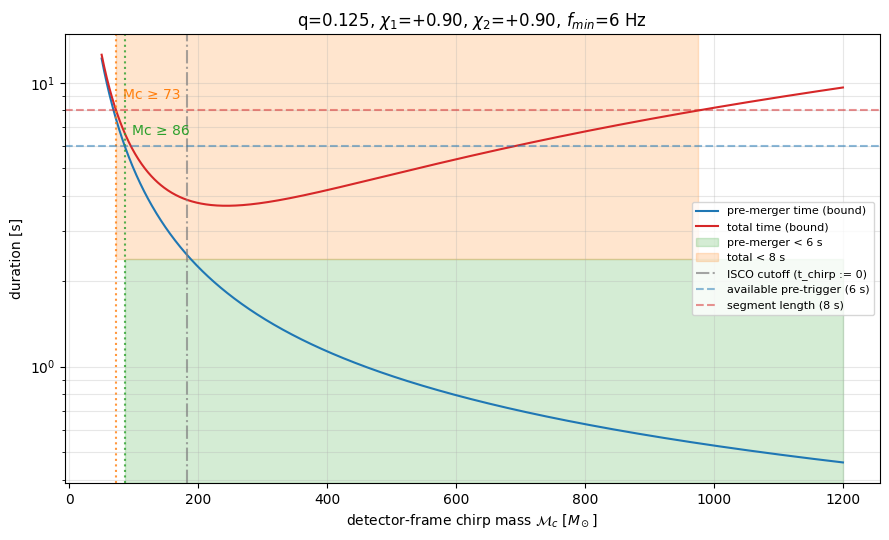

In [51]:
import matplotlib.pyplot as plt

Q_FIX, CHI1_FIX, CHI2_FIX = 0.125, 0.9, 0.9
T_PRE_AVAIL, T_TOT_AVAIL = 6.0, 8.0
mc_grid = np.arange(MC_RANGE[0], MC_RANGE[1] + 1e-9, 1.0)   # steps of 5 Msun
CHECK_WAVEFORM = False   # True: overlay actual waveform durations (slow, can fail at high mass)


mc_ok, t_pre_arr, t_tot_arr, m_tot_arr = [], [], [], []
for mc in mc_grid:
    m1, m2 = comp_masses(mc, Q_FIX)
    if not in_prior(m1, m2):
        continue
    t_pre, t_post = duration_bound(m1, m2, CHI1_FIX, CHI2_FIX)
    mc_ok.append(mc)
    t_pre_arr.append(t_pre)
    t_tot_arr.append(t_pre + t_post)
    m_tot_arr.append(m1 + m2)

mc_ok, t_pre_arr, t_tot_arr, m_tot_arr = map(np.array, (mc_ok, t_pre_arr, t_tot_arr, m_tot_arr))


def mask_to_intervals(mask):
    """Contiguous True runs of a boolean mask -> list of (mc_lo, mc_hi)."""
    idx = np.flatnonzero(mask)
    if not len(idx):
        return []
    return [(mc_ok[g[0]], mc_ok[g[-1]])
            for g in np.split(idx, np.flatnonzero(np.diff(idx) > 1) + 1)]


fits_pre  = t_pre_arr < T_PRE_AVAIL
fits_tot  = t_tot_arr < T_TOT_AVAIL
fits_both = fits_pre & fits_tot

int_pre, int_tot, int_both = map(mask_to_intervals, (fits_pre, fits_tot, fits_both))

# chirp mass above which the crude ISCO cutoff sets t_chirp = 0 (f_min >= 4397/M)
cut_idx = np.flatnonzero(F_MIN >= 4397.0 / m_tot_arr)
mc_cut = mc_ok[cut_idx[0]] if len(cut_idx) else None


def report(label, intervals):
    if intervals:
        for lo, hi in intervals:
            print(f"{label}: Mc in [{lo:.0f}, {hi:.0f}] Msun")
    else:
        print(f"{label}: never in the scanned range")


print(f"q={Q_FIX}, chi1={CHI1_FIX:+.2f}, chi2={CHI2_FIX:+.2f}, f_min={F_MIN:g} Hz")
report(f"pre-merger time < {T_PRE_AVAIL:g} s", int_pre)
report(f"total time      < {T_TOT_AVAIL:g} s", int_tot)
report("both conditions         ", int_both)
if mc_cut is not None:
    print(f"note: for Mc >= {mc_cut:.0f} Msun the bound uses t_chirp = 0 (f_min above ISCO estimate)")

# ---- plot ----
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(mc_ok, t_pre_arr, color="tab:blue", label="pre-merger time (bound)")
ax.plot(mc_ok, t_tot_arr, color="tab:red",  label="total time (bound)")

# pre-merger < 6 s: lower half of the axes (green); total < 8 s: upper half (orange)
for i, (lo, hi) in enumerate(int_pre):
    ax.axvspan(lo, hi, ymin=0.0, ymax=0.5, color="tab:green", alpha=0.2,
               label=f"pre-merger < {T_PRE_AVAIL:g} s" if i == 0 else None)
    ax.axvline(lo, color="tab:green", ls=":", alpha=0.8)
for i, (lo, hi) in enumerate(int_tot):
    ax.axvspan(lo, hi, ymin=0.5, ymax=1.0, color="tab:orange", alpha=0.2,
               label=f"total < {T_TOT_AVAIL:g} s" if i == 0 else None)
    ax.axvline(lo, color="tab:orange", ls=":", alpha=0.8)

if int_pre:
    ax.annotate(f"Mc ≥ {int_pre[0][0]:.0f}", xy=(int_pre[0][0], T_PRE_AVAIL),
                xytext=(5, 8), textcoords="offset points", color="tab:green")
if int_tot:
    ax.annotate(f"Mc ≥ {int_tot[0][0]:.0f}", xy=(int_tot[0][0], T_TOT_AVAIL),
                xytext=(5, 8), textcoords="offset points", color="tab:orange")

if mc_cut is not None:
    ax.axvline(mc_cut, color="gray", ls="-.", alpha=0.7, label="ISCO cutoff (t_chirp := 0)")


ax.axhline(T_PRE_AVAIL, color="tab:blue", ls="--", alpha=0.5, label="available pre-trigger (6 s)")
ax.axhline(T_TOT_AVAIL, color="tab:red",  ls="--", alpha=0.5, label="segment length (8 s)")

ax.set_xlabel(r"detector-frame chirp mass $\mathcal{M}_c$ [$M_\odot$]")
ax.set_ylabel("duration [s]")
ax.set_yscale("log")
ax.set_title(f"q={Q_FIX}, $\\chi_1$={CHI1_FIX:+.2f}, $\\chi_2$={CHI2_FIX:+.2f}, $f_{{min}}$={F_MIN:g} Hz")
ax.grid(alpha=0.3, which="both")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

q=1.0, chi1=+0.90, chi2=+0.90, f_min=6 Hz
pre-merger time < 6 s: Mc in [77, 1200] Msun
total time      < 8 s: Mc in [64, 1200] Msun
both conditions         : Mc in [77, 1200] Msun
note: for Mc >= 319 Msun the bound uses t_chirp = 0 (f_min above ISCO estimate)


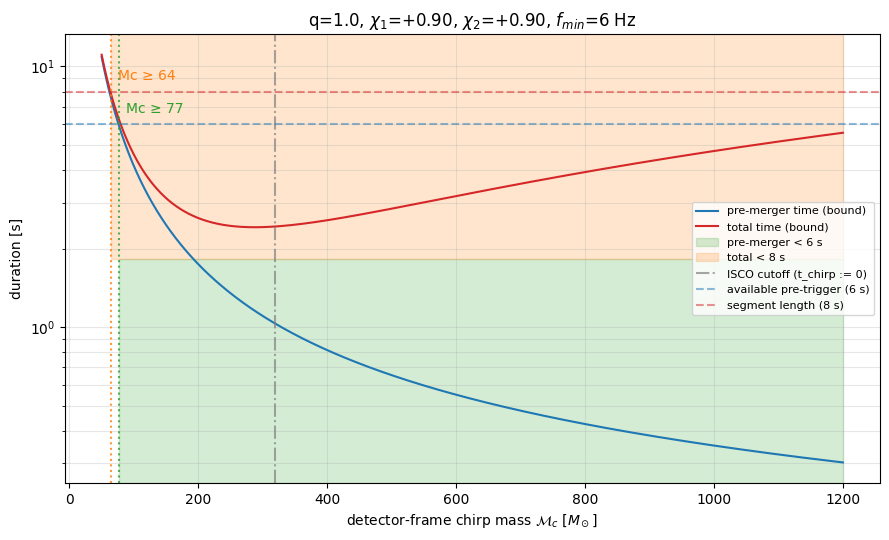

In [49]:
import matplotlib.pyplot as plt

Q_FIX, CHI1_FIX, CHI2_FIX = 1.0, 0.9, 0.9
T_PRE_AVAIL, T_TOT_AVAIL = 6.0, 8.0
mc_grid = np.arange(MC_RANGE[0], MC_RANGE[1] + 1e-9, 1.0)   # steps of 5 Msun
CHECK_WAVEFORM = False   # True: overlay actual waveform durations (slow, can fail at high mass)

mc_ok, t_pre_arr, t_tot_arr, m_tot_arr = [], [], [], []
for mc in mc_grid:
    m1, m2 = comp_masses(mc, Q_FIX)
    if not in_prior(m1, m2):
        continue
    t_pre, t_post = duration_bound(m1, m2, CHI1_FIX, CHI2_FIX)
    mc_ok.append(mc)
    t_pre_arr.append(t_pre)
    t_tot_arr.append(t_pre + t_post)
    m_tot_arr.append(m1 + m2)

mc_ok, t_pre_arr, t_tot_arr, m_tot_arr = map(np.array, (mc_ok, t_pre_arr, t_tot_arr, m_tot_arr))


def mask_to_intervals(mask):
    """Contiguous True runs of a boolean mask -> list of (mc_lo, mc_hi)."""
    idx = np.flatnonzero(mask)
    if not len(idx):
        return []
    return [(mc_ok[g[0]], mc_ok[g[-1]])
            for g in np.split(idx, np.flatnonzero(np.diff(idx) > 1) + 1)]


fits_pre  = t_pre_arr < T_PRE_AVAIL
fits_tot  = t_tot_arr < T_TOT_AVAIL
fits_both = fits_pre & fits_tot

int_pre, int_tot, int_both = map(mask_to_intervals, (fits_pre, fits_tot, fits_both))

# chirp mass above which the crude ISCO cutoff sets t_chirp = 0 (f_min >= 4397/M)
cut_idx = np.flatnonzero(F_MIN >= 4397.0 / m_tot_arr)
mc_cut = mc_ok[cut_idx[0]] if len(cut_idx) else None


def report(label, intervals):
    if intervals:
        for lo, hi in intervals:
            print(f"{label}: Mc in [{lo:.0f}, {hi:.0f}] Msun")
    else:
        print(f"{label}: never in the scanned range")


print(f"q={Q_FIX}, chi1={CHI1_FIX:+.2f}, chi2={CHI2_FIX:+.2f}, f_min={F_MIN:g} Hz")
report(f"pre-merger time < {T_PRE_AVAIL:g} s", int_pre)
report(f"total time      < {T_TOT_AVAIL:g} s", int_tot)
report("both conditions         ", int_both)
if mc_cut is not None:
    print(f"note: for Mc >= {mc_cut:.0f} Msun the bound uses t_chirp = 0 (f_min above ISCO estimate)")

# ---- plot ----
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(mc_ok, t_pre_arr, color="tab:blue", label="pre-merger time (bound)")
ax.plot(mc_ok, t_tot_arr, color="tab:red",  label="total time (bound)")

# pre-merger < 6 s: lower half of the axes (green); total < 8 s: upper half (orange)
for i, (lo, hi) in enumerate(int_pre):
    ax.axvspan(lo, hi, ymin=0.0, ymax=0.5, color="tab:green", alpha=0.2,
               label=f"pre-merger < {T_PRE_AVAIL:g} s" if i == 0 else None)
    ax.axvline(lo, color="tab:green", ls=":", alpha=0.8)
for i, (lo, hi) in enumerate(int_tot):
    ax.axvspan(lo, hi, ymin=0.5, ymax=1.0, color="tab:orange", alpha=0.2,
               label=f"total < {T_TOT_AVAIL:g} s" if i == 0 else None)
    ax.axvline(lo, color="tab:orange", ls=":", alpha=0.8)

if int_pre:
    ax.annotate(f"Mc ≥ {int_pre[0][0]:.0f}", xy=(int_pre[0][0], T_PRE_AVAIL),
                xytext=(5, 8), textcoords="offset points", color="tab:green")
if int_tot:
    ax.annotate(f"Mc ≥ {int_tot[0][0]:.0f}", xy=(int_tot[0][0], T_TOT_AVAIL),
                xytext=(5, 8), textcoords="offset points", color="tab:orange")

if mc_cut is not None:
    ax.axvline(mc_cut, color="gray", ls="-.", alpha=0.7, label="ISCO cutoff (t_chirp := 0)")

if CHECK_WAVEFORM:
    wf_mc, wf_pre, wf_tot = [], [], []
    for mc in mc_ok[::10]:                      # every 50 Msun to save time
        m1, m2 = comp_masses(mc, Q_FIX)
        try:
            p, q_ = duration_waveform(m1, m2, CHI1_FIX, CHI2_FIX)
        except Exception:
            continue
        wf_mc.append(mc); wf_pre.append(p); wf_tot.append(p + q_)
    ax.plot(wf_mc, wf_pre, "o", color="tab:blue", mfc="none", label="pre-merger (waveform)")
    ax.plot(wf_mc, wf_tot, "o", color="tab:red",  mfc="none", label="total (waveform)")

ax.axhline(T_PRE_AVAIL, color="tab:blue", ls="--", alpha=0.5, label="available pre-trigger (6 s)")
ax.axhline(T_TOT_AVAIL, color="tab:red",  ls="--", alpha=0.5, label="segment length (8 s)")

ax.set_xlabel(r"detector-frame chirp mass $\mathcal{M}_c$ [$M_\odot$]")
ax.set_ylabel("duration [s]")
ax.set_yscale("log")
ax.set_title(f"q={Q_FIX}, $\\chi_1$={CHI1_FIX:+.2f}, $\\chi_2$={CHI2_FIX:+.2f}, $f_{{min}}$={F_MIN:g} Hz")
ax.grid(alpha=0.3, which="both")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [53]:
import matplotlib.pyplot as plt

def plot_duration_vs_chirp_mass(
    mc_range=(50.0, 1200.0),     # detector-frame chirp mass range [Msun]
    m1_range=(50.0, 4500.0),     # component mass priors (Constraint)
    m2_range=(20.0, 1500.0),
    q=0.125,                     # fixed mass ratio
    chi1=0.9,                    # fixed aligned spins
    chi2=0.9,
    f_min=6.0,                   # Hz
    t_pre_avail=6.0,             # s available before the trigger
    t_tot_avail=8.0,             # s segment length
    mc_step=1.0,                 # chirp mass step [Msun]
    plot=True,
):
    """Bound on pre-merger / total signal duration vs chirp mass for fixed q, chi1, chi2.
    Prints and shades the Mc intervals where pre < t_pre_avail and total < t_tot_avail.
    Returns a dict with the arrays and intervals."""

    def in_prior(m1, m2):
        return (m1_range[0] <= m1 <= m1_range[1]) and (m2_range[0] <= m2 <= m2_range[1])

    mc_grid = np.arange(mc_range[0], mc_range[1] + 1e-9, mc_step)

    mc_ok, t_pre_arr, t_tot_arr, m_tot_arr = [], [], [], []
    for mc in mc_grid:
        m1, m2 = comp_masses(mc, q)
        if not in_prior(m1, m2):
            continue
        t_pre, t_post = duration_bound(m1, m2, chi1, chi2, f_min=f_min)
        mc_ok.append(mc)
        t_pre_arr.append(t_pre)
        t_tot_arr.append(t_pre + t_post)
        m_tot_arr.append(m1 + m2)

    mc_ok, t_pre_arr, t_tot_arr, m_tot_arr = map(np.array, (mc_ok, t_pre_arr, t_tot_arr, m_tot_arr))

    def mask_to_intervals(mask):
        """Contiguous True runs of a boolean mask -> list of (mc_lo, mc_hi)."""
        idx = np.flatnonzero(mask)
        if not len(idx):
            return []
        return [(mc_ok[g[0]], mc_ok[g[-1]])
                for g in np.split(idx, np.flatnonzero(np.diff(idx) > 1) + 1)]

    fits_pre  = t_pre_arr < t_pre_avail
    fits_tot  = t_tot_arr < t_tot_avail
    fits_both = fits_pre & fits_tot
    int_pre, int_tot, int_both = map(mask_to_intervals, (fits_pre, fits_tot, fits_both))

    # chirp mass above which the crude ISCO cutoff sets t_chirp = 0 (f_min >= 4397/M)
    cut_idx = np.flatnonzero(f_min >= 4397.0 / m_tot_arr)
    mc_cut = mc_ok[cut_idx[0]] if len(cut_idx) else None

    def report(label, intervals):
        if intervals:
            for lo, hi in intervals:
                print(f"{label}: Mc in [{lo:.0f}, {hi:.0f}] Msun")
        else:
            print(f"{label}: never in the scanned range")

    print(f"q={q}, chi1={chi1:+.2f}, chi2={chi2:+.2f}, f_min={f_min:g} Hz")
    report(f"pre-merger time < {t_pre_avail:g} s", int_pre)
    report(f"total time      < {t_tot_avail:g} s", int_tot)
    report("both conditions         ", int_both)
    if mc_cut is not None:
        print(f"note: for Mc >= {mc_cut:.0f} Msun the bound uses t_chirp = 0 (f_min above ISCO estimate)")

    if plot:
        fig, ax = plt.subplots(figsize=(9, 5.5))
        ax.plot(mc_ok, t_pre_arr, color="tab:blue", label="pre-merger time (bound)")
        ax.plot(mc_ok, t_tot_arr, color="tab:red",  label="total time (bound)")

        # pre-merger < t_pre_avail: lower half (green); total < t_tot_avail: upper half (orange)
        for i, (lo, hi) in enumerate(int_pre):
            ax.axvspan(lo, hi, ymin=0.0, ymax=0.5, color="tab:green", alpha=0.2,
                       label=f"pre-merger < {t_pre_avail:g} s" if i == 0 else None)
            ax.axvline(lo, color="tab:green", ls=":", alpha=0.8)
        for i, (lo, hi) in enumerate(int_tot):
            ax.axvspan(lo, hi, ymin=0.5, ymax=1.0, color="tab:orange", alpha=0.2,
                       label=f"total < {t_tot_avail:g} s" if i == 0 else None)
            ax.axvline(lo, color="tab:orange", ls=":", alpha=0.8)

        if int_pre:
            ax.annotate(f"Mc ≥ {int_pre[0][0]:.0f}", xy=(int_pre[0][0], t_pre_avail),
                        xytext=(5, 8), textcoords="offset points", color="tab:green")
        if int_tot:
            ax.annotate(f"Mc ≥ {int_tot[0][0]:.0f}", xy=(int_tot[0][0], t_tot_avail),
                        xytext=(5, 8), textcoords="offset points", color="tab:orange")

        if mc_cut is not None:
            ax.axvline(mc_cut, color="gray", ls="-.", alpha=0.7, label="ISCO cutoff (t_chirp := 0)")

        ax.axhline(t_pre_avail, color="tab:blue", ls="--", alpha=0.5,
                   label=f"available pre-trigger ({t_pre_avail:g} s)")
        ax.axhline(t_tot_avail, color="tab:red", ls="--", alpha=0.5,
                   label=f"segment length ({t_tot_avail:g} s)")

        ax.set_xlabel(r"detector-frame chirp mass $\mathcal{M}_c$ [$M_\odot$]")
        ax.set_ylabel("duration [s]")
        ax.set_yscale("log")
        ax.set_title(f"q={q}, $\\chi_1$={chi1:+.2f}, $\\chi_2$={chi2:+.2f}, $f_{{min}}$={f_min:g} Hz")
        ax.grid(alpha=0.3, which="both")
        ax.legend(fontsize=8)
        plt.tight_layout()
        plt.show()

    return dict(mc=mc_ok, t_pre=t_pre_arr, t_tot=t_tot_arr, m_tot=m_tot_arr,
                intervals_pre=int_pre, intervals_tot=int_tot, intervals_both=int_both,
                mc_isco_cut=mc_cut)

q=0.125, chi1=+0.90, chi2=+0.90, f_min=6 Hz
pre-merger time < 6 s: Mc in [86, 1200] Msun
total time      < 8 s: Mc in [73, 975] Msun
both conditions         : Mc in [86, 975] Msun
note: for Mc >= 183 Msun the bound uses t_chirp = 0 (f_min above ISCO estimate)


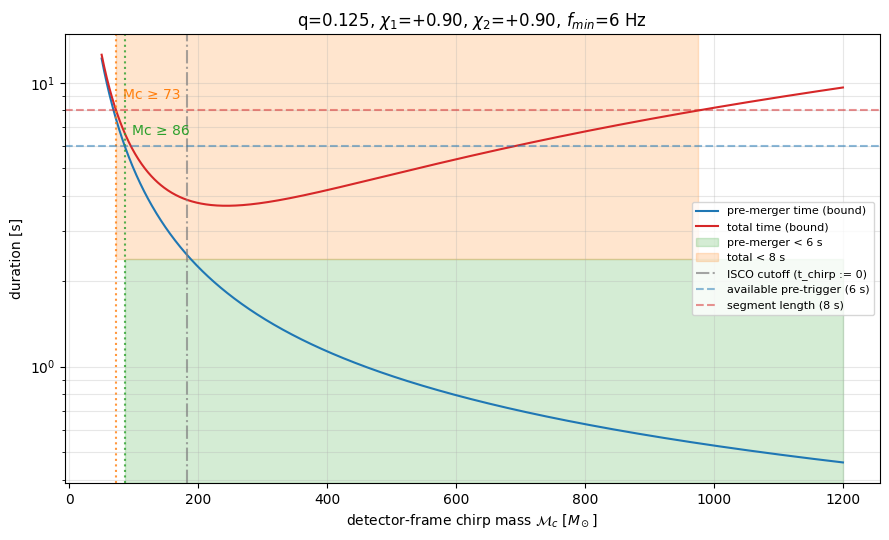

{'mc': array([  50.,   51.,   52., ..., 1198., 1199., 1200.]),
 't_pre': array([12.19519151, 11.86978289, 11.55995135, ...,  0.46021425,
         0.45993048,  0.45964715]),
 't_tot': array([12.5777035 , 12.25994512, 11.95776382, ...,  9.62520154,
         9.632568  ,  9.63993492]),
 'm_tot': array([ 200.54277652,  204.55363205,  208.56448758, ..., 4805.00492545,
        4809.01578098, 4813.02663651]),
 'intervals_pre': [(86.0, 1200.0)],
 'intervals_tot': [(73.0, 975.0)],
 'intervals_both': [(86.0, 975.0)],
 'mc_isco_cut': 183.0}

In [54]:
plot_duration_vs_chirp_mass()

q=0.125, chi1=+0.90, chi2=+0.90, f_min=6 Hz
pre-merger time < 12 s: Mc in [51, 1200] Msun
total time      < 16 s: Mc in [50, 1200] Msun
both conditions         : Mc in [51, 1200] Msun
note: for Mc >= 183 Msun the bound uses t_chirp = 0 (f_min above ISCO estimate)


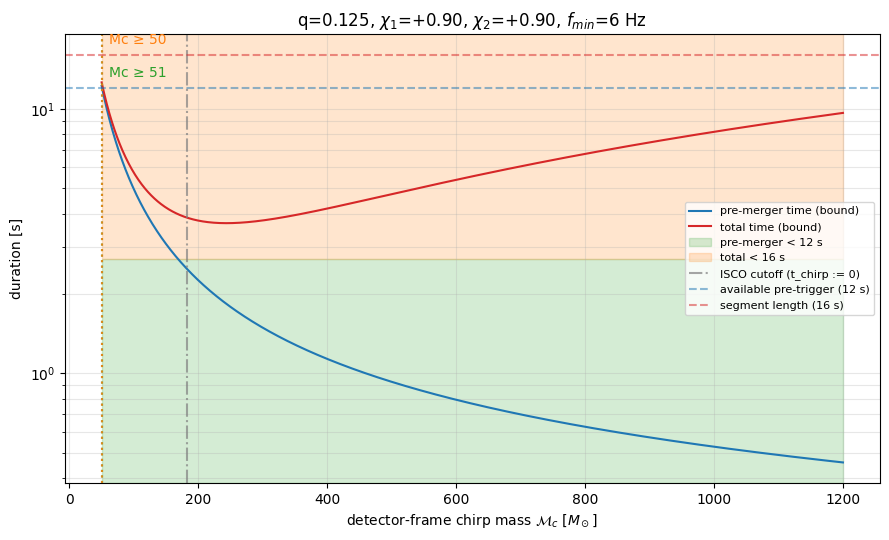

{'mc': array([  50.,   51.,   52., ..., 1198., 1199., 1200.]),
 't_pre': array([12.19519151, 11.86978289, 11.55995135, ...,  0.46021425,
         0.45993048,  0.45964715]),
 't_tot': array([12.5777035 , 12.25994512, 11.95776382, ...,  9.62520154,
         9.632568  ,  9.63993492]),
 'm_tot': array([ 200.54277652,  204.55363205,  208.56448758, ..., 4805.00492545,
        4809.01578098, 4813.02663651]),
 'intervals_pre': [(51.0, 1200.0)],
 'intervals_tot': [(50.0, 1200.0)],
 'intervals_both': [(51.0, 1200.0)],
 'mc_isco_cut': 183.0}

In [55]:
plot_duration_vs_chirp_mass(
    t_pre_avail=12.0, t_tot_avail=16.0
)

q=0.125, chi1=+0.90, chi2=+0.90, f_min=6 Hz
pre-merger time < 24 s: Mc in [31, 1000] Msun
total time      < 32 s: Mc in [26, 1000] Msun
both conditions         : Mc in [31, 1000] Msun
note: for Mc >= 183 Msun the bound uses t_chirp = 0 (f_min above ISCO estimate)


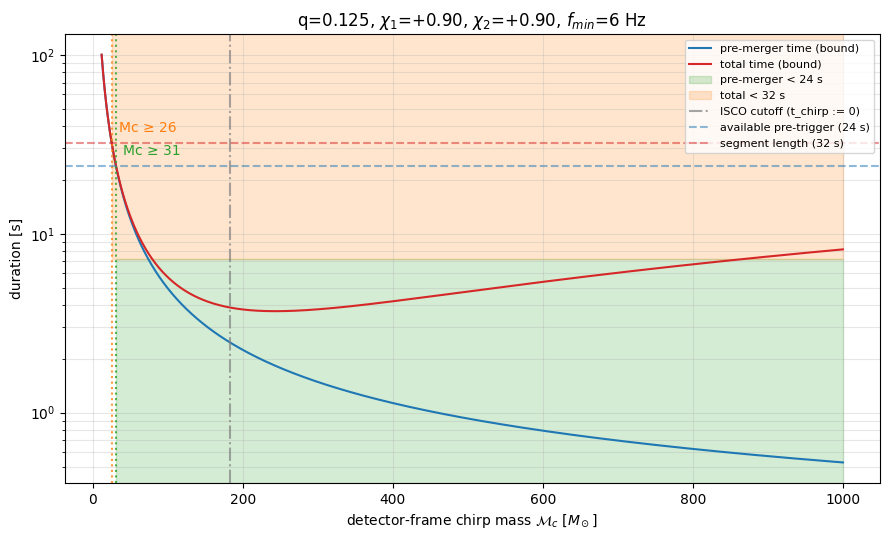

{'mc': array([  12.,   13.,   14.,   15.,   16.,   17.,   18.,   19.,   20.,
          21.,   22.,   23.,   24.,   25.,   26.,   27.,   28.,   29.,
          30.,   31.,   32.,   33.,   34.,   35.,   36.,   37.,   38.,
          39.,   40.,   41.,   42.,   43.,   44.,   45.,   46.,   47.,
          48.,   49.,   50.,   51.,   52.,   53.,   54.,   55.,   56.,
          57.,   58.,   59.,   60.,   61.,   62.,   63.,   64.,   65.,
          66.,   67.,   68.,   69.,   70.,   71.,   72.,   73.,   74.,
          75.,   76.,   77.,   78.,   79.,   80.,   81.,   82.,   83.,
          84.,   85.,   86.,   87.,   88.,   89.,   90.,   91.,   92.,
          93.,   94.,   95.,   96.,   97.,   98.,   99.,  100.,  101.,
         102.,  103.,  104.,  105.,  106.,  107.,  108.,  109.,  110.,
         111.,  112.,  113.,  114.,  115.,  116.,  117.,  118.,  119.,
         120.,  121.,  122.,  123.,  124.,  125.,  126.,  127.,  128.,
         129.,  130.,  131.,  132.,  133.,  134.,  135.,  136.,  137.,


In [58]:
plot_duration_vs_chirp_mass(
    mc_range=(10.0, 1000.0),
    m1_range=(10.0, 5000.0), m2_range=(5.0, 2000.0),
    t_pre_avail=24.0, t_tot_avail=32.0
)

q=0.125, chi1=+0.90, chi2=+0.90, f_min=6 Hz
pre-merger time < 96 s: Mc in [13, 1000] Msun
total time      < 128 s: Mc in [12, 1000] Msun
both conditions         : Mc in [13, 1000] Msun
note: for Mc >= 183 Msun the bound uses t_chirp = 0 (f_min above ISCO estimate)


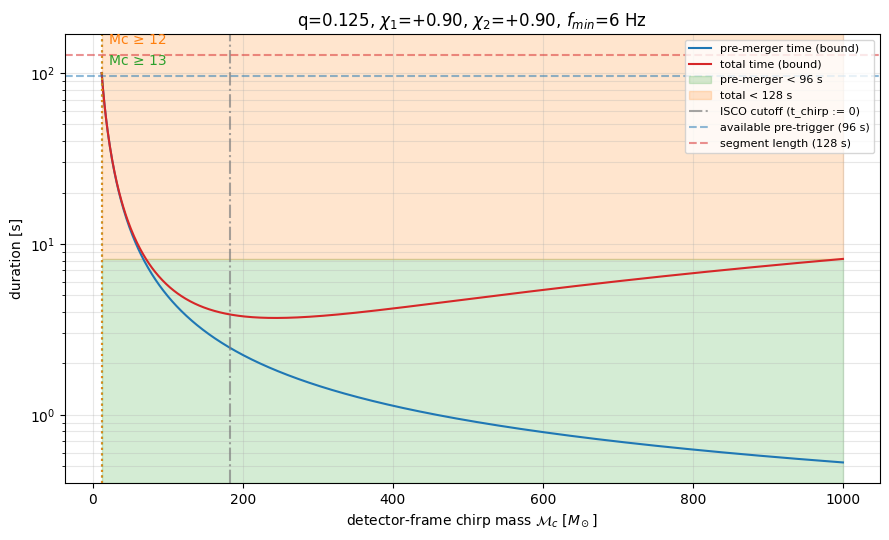

{'mc': array([  12.,   13.,   14.,   15.,   16.,   17.,   18.,   19.,   20.,
          21.,   22.,   23.,   24.,   25.,   26.,   27.,   28.,   29.,
          30.,   31.,   32.,   33.,   34.,   35.,   36.,   37.,   38.,
          39.,   40.,   41.,   42.,   43.,   44.,   45.,   46.,   47.,
          48.,   49.,   50.,   51.,   52.,   53.,   54.,   55.,   56.,
          57.,   58.,   59.,   60.,   61.,   62.,   63.,   64.,   65.,
          66.,   67.,   68.,   69.,   70.,   71.,   72.,   73.,   74.,
          75.,   76.,   77.,   78.,   79.,   80.,   81.,   82.,   83.,
          84.,   85.,   86.,   87.,   88.,   89.,   90.,   91.,   92.,
          93.,   94.,   95.,   96.,   97.,   98.,   99.,  100.,  101.,
         102.,  103.,  104.,  105.,  106.,  107.,  108.,  109.,  110.,
         111.,  112.,  113.,  114.,  115.,  116.,  117.,  118.,  119.,
         120.,  121.,  122.,  123.,  124.,  125.,  126.,  127.,  128.,
         129.,  130.,  131.,  132.,  133.,  134.,  135.,  136.,  137.,


In [62]:
plot_duration_vs_chirp_mass(
    mc_range=(10.0, 1000.0),
    m1_range=(10.0, 5000.0), m2_range=(5.0, 2000.0),
    t_pre_avail=96.0, t_tot_avail=128.0, f_min=6.0
)

q=0.125, chi1=+0.90, chi2=+0.90, f_min=2 Hz
pre-merger time < 96 s: Mc in [77, 1000] Msun
total time      < 128 s: Mc in [63, 1000] Msun
both conditions         : Mc in [77, 1000] Msun
note: for Mc >= 549 Msun the bound uses t_chirp = 0 (f_min above ISCO estimate)


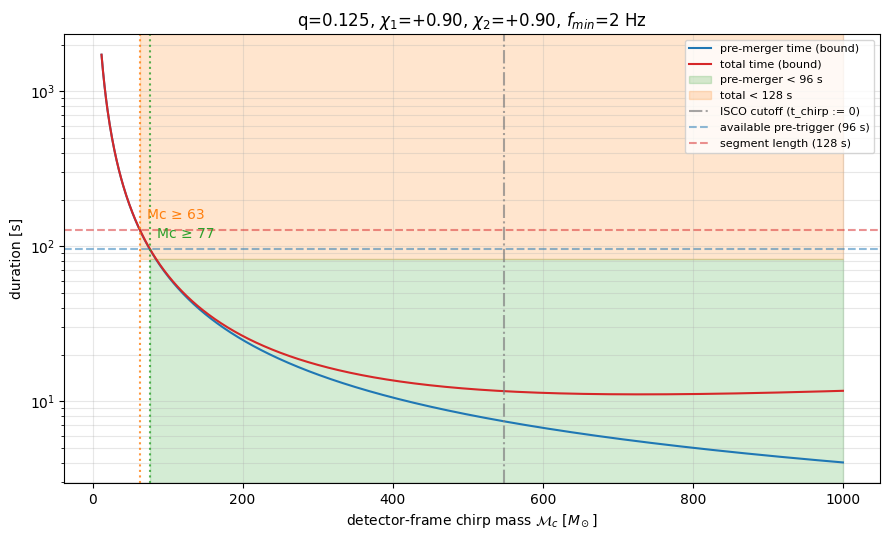

{'mc': array([  12.,   13.,   14.,   15.,   16.,   17.,   18.,   19.,   20.,
          21.,   22.,   23.,   24.,   25.,   26.,   27.,   28.,   29.,
          30.,   31.,   32.,   33.,   34.,   35.,   36.,   37.,   38.,
          39.,   40.,   41.,   42.,   43.,   44.,   45.,   46.,   47.,
          48.,   49.,   50.,   51.,   52.,   53.,   54.,   55.,   56.,
          57.,   58.,   59.,   60.,   61.,   62.,   63.,   64.,   65.,
          66.,   67.,   68.,   69.,   70.,   71.,   72.,   73.,   74.,
          75.,   76.,   77.,   78.,   79.,   80.,   81.,   82.,   83.,
          84.,   85.,   86.,   87.,   88.,   89.,   90.,   91.,   92.,
          93.,   94.,   95.,   96.,   97.,   98.,   99.,  100.,  101.,
         102.,  103.,  104.,  105.,  106.,  107.,  108.,  109.,  110.,
         111.,  112.,  113.,  114.,  115.,  116.,  117.,  118.,  119.,
         120.,  121.,  122.,  123.,  124.,  125.,  126.,  127.,  128.,
         129.,  130.,  131.,  132.,  133.,  134.,  135.,  136.,  137.,


In [61]:
plot_duration_vs_chirp_mass(
    mc_range=(10.0, 1000.0),
    m1_range=(10.0, 5000.0), m2_range=(5.0, 2000.0),
    t_pre_avail=96.0, t_tot_avail=128.0, f_min=2.0
)